# Fit cuối và đánh giá Test

Mở từ thư mục dự án với kernel của môi trường dự án. Các ô đọc config, bảng và hình đã công bố.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display

here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "reports/stage5_inputs.json").is_file())
sys.path.insert(0, str(root))
from src.wrmsse_stage5 import STAGE2, STAGE3, STAGE4, SELECTED, TABLES, csv, read, check_gates
check_gates()

def table(name):
    return csv(TABLES / (name + ".csv"))

def figure(number):
    path, = (root / "reports/figures").glob(f"{number:02d}_*.png")
    display(Image(filename=str(path), width=950))


Giai đoạn 4 đã fit một rừng mới trên mẫu Train + Validation. Actual chỉ được mở qua gate sau khi khóa model, ma trận và hai dự báo. Seasonal Naive lặp bảy ngày cuối trước d_1914. [Pipeline fit và đánh giá](../src/wrmsse_stage4.py) · [Báo cáo Giai đoạn 4](../docs/STAGE4_REPORT.md).

{'model': 'RandomForestRegressor',
 'candidate': 'RF-15 + FE-04',
 'selected_model': 'results/wrmsse_v1/stage3_20261124T082126Z/selection_v2/selected_model.json',
 'selected_model_sha256': 'f8a186696cacb518993c1e9899b16b982b76557c77dd6708d092bb129f0882b6',
 'params': {'bootstrap': True,
  'ccp_alpha': 0.0,
  'criterion': 'squared_error',
  'max_depth': 20,
  'max_features': 0.5,
  'max_leaf_nodes': None,
  'max_samples': 0.5,
  'min_impurity_decrease': 0.0,
  'min_samples_leaf': 5,
  'min_samples_split': 2,
  'min_weight_fraction_leaf': 0.0,
  'monotonic_cst': None,
  'n_estimators': 150,
  'n_jobs': 8,
  'oob_score': False,
  'random_state': 42,
  'verbose': 0,
  'warm_start': False},
 'train_scope': [1, 1913],
 'train_rows': 609185,
 'logical_features': 15,
 'encoded_features': 3082,
 'forecast_origin': 1913,
 'horizon': 28,
 'fit_count': 1}

{'fit_seconds': 224.92189979999966,
 'predict_seconds': 2.3441765000025043,
 'peak_worker_rss_mib': 1483.71875,
 'n_jobs': 8,
 'versions': {'python': '3.12.10',
  'scikit-learn': '1.9.1',
  'numpy': '2.5.5',
  'pandas': '3.1.1',
  'scipy': '1.18.1',
  'joblib': '1.6.0',
  'pyarrow': '26.0.1',
  'psutil': '7.2.2'}}

,model,wrmsse,mae,rmse,wape_percent,forecast_bias_percent,actual_sales,forecast_sales,sales_difference,overforecast_percent,underforecast_percent,metric_grain
0,random_forest,0.703912,1.084987,2.232722,75.199038,-4.327880,1231764.0,1.178455e+06,-53309.265062,0.0,4.327880,MAE/RMSE/WAPE/Bias: item-store-day. WRMSSE: 12...
1,seasonal_naive,0.869701,1.243972,2.676895,86.218139,-7.359202,1231764.0,1.141116e+06,-90648.000000,0.0,7.359202,MAE/RMSE/WAPE/Bias: item-store-day. WRMSSE: 12...


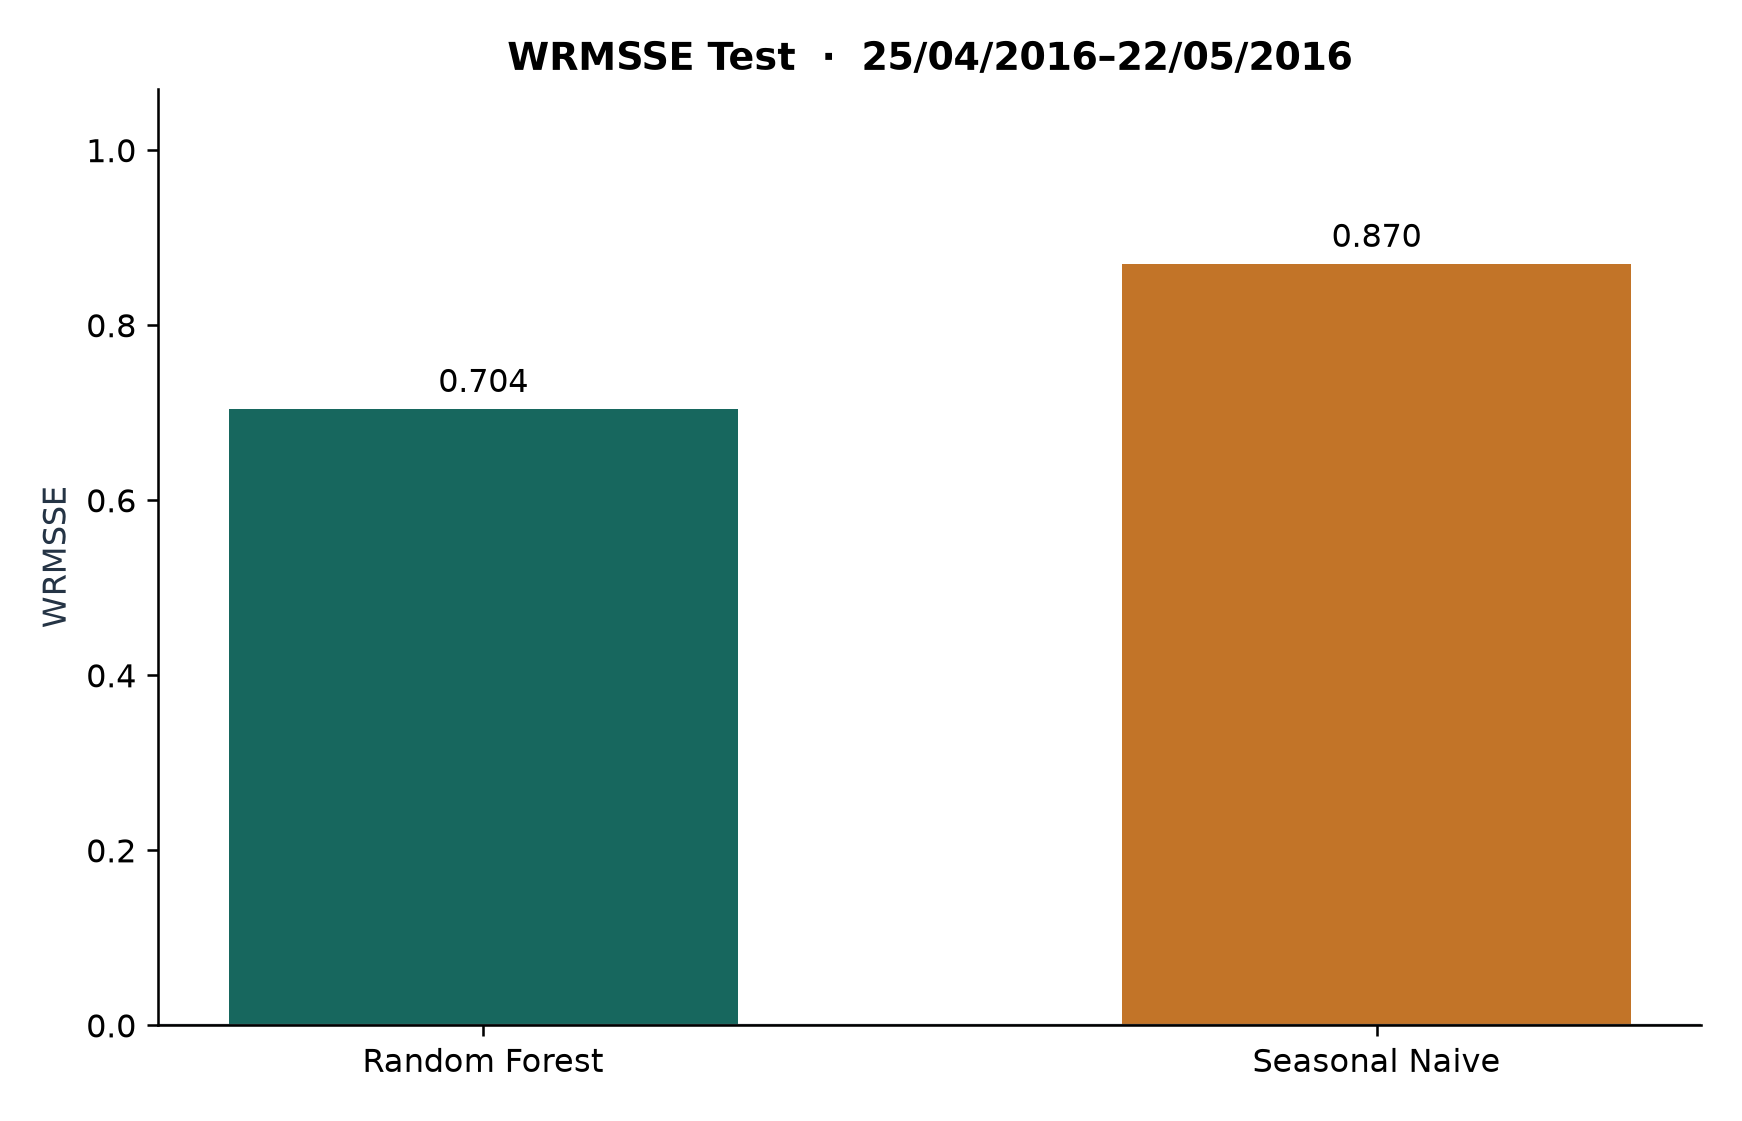

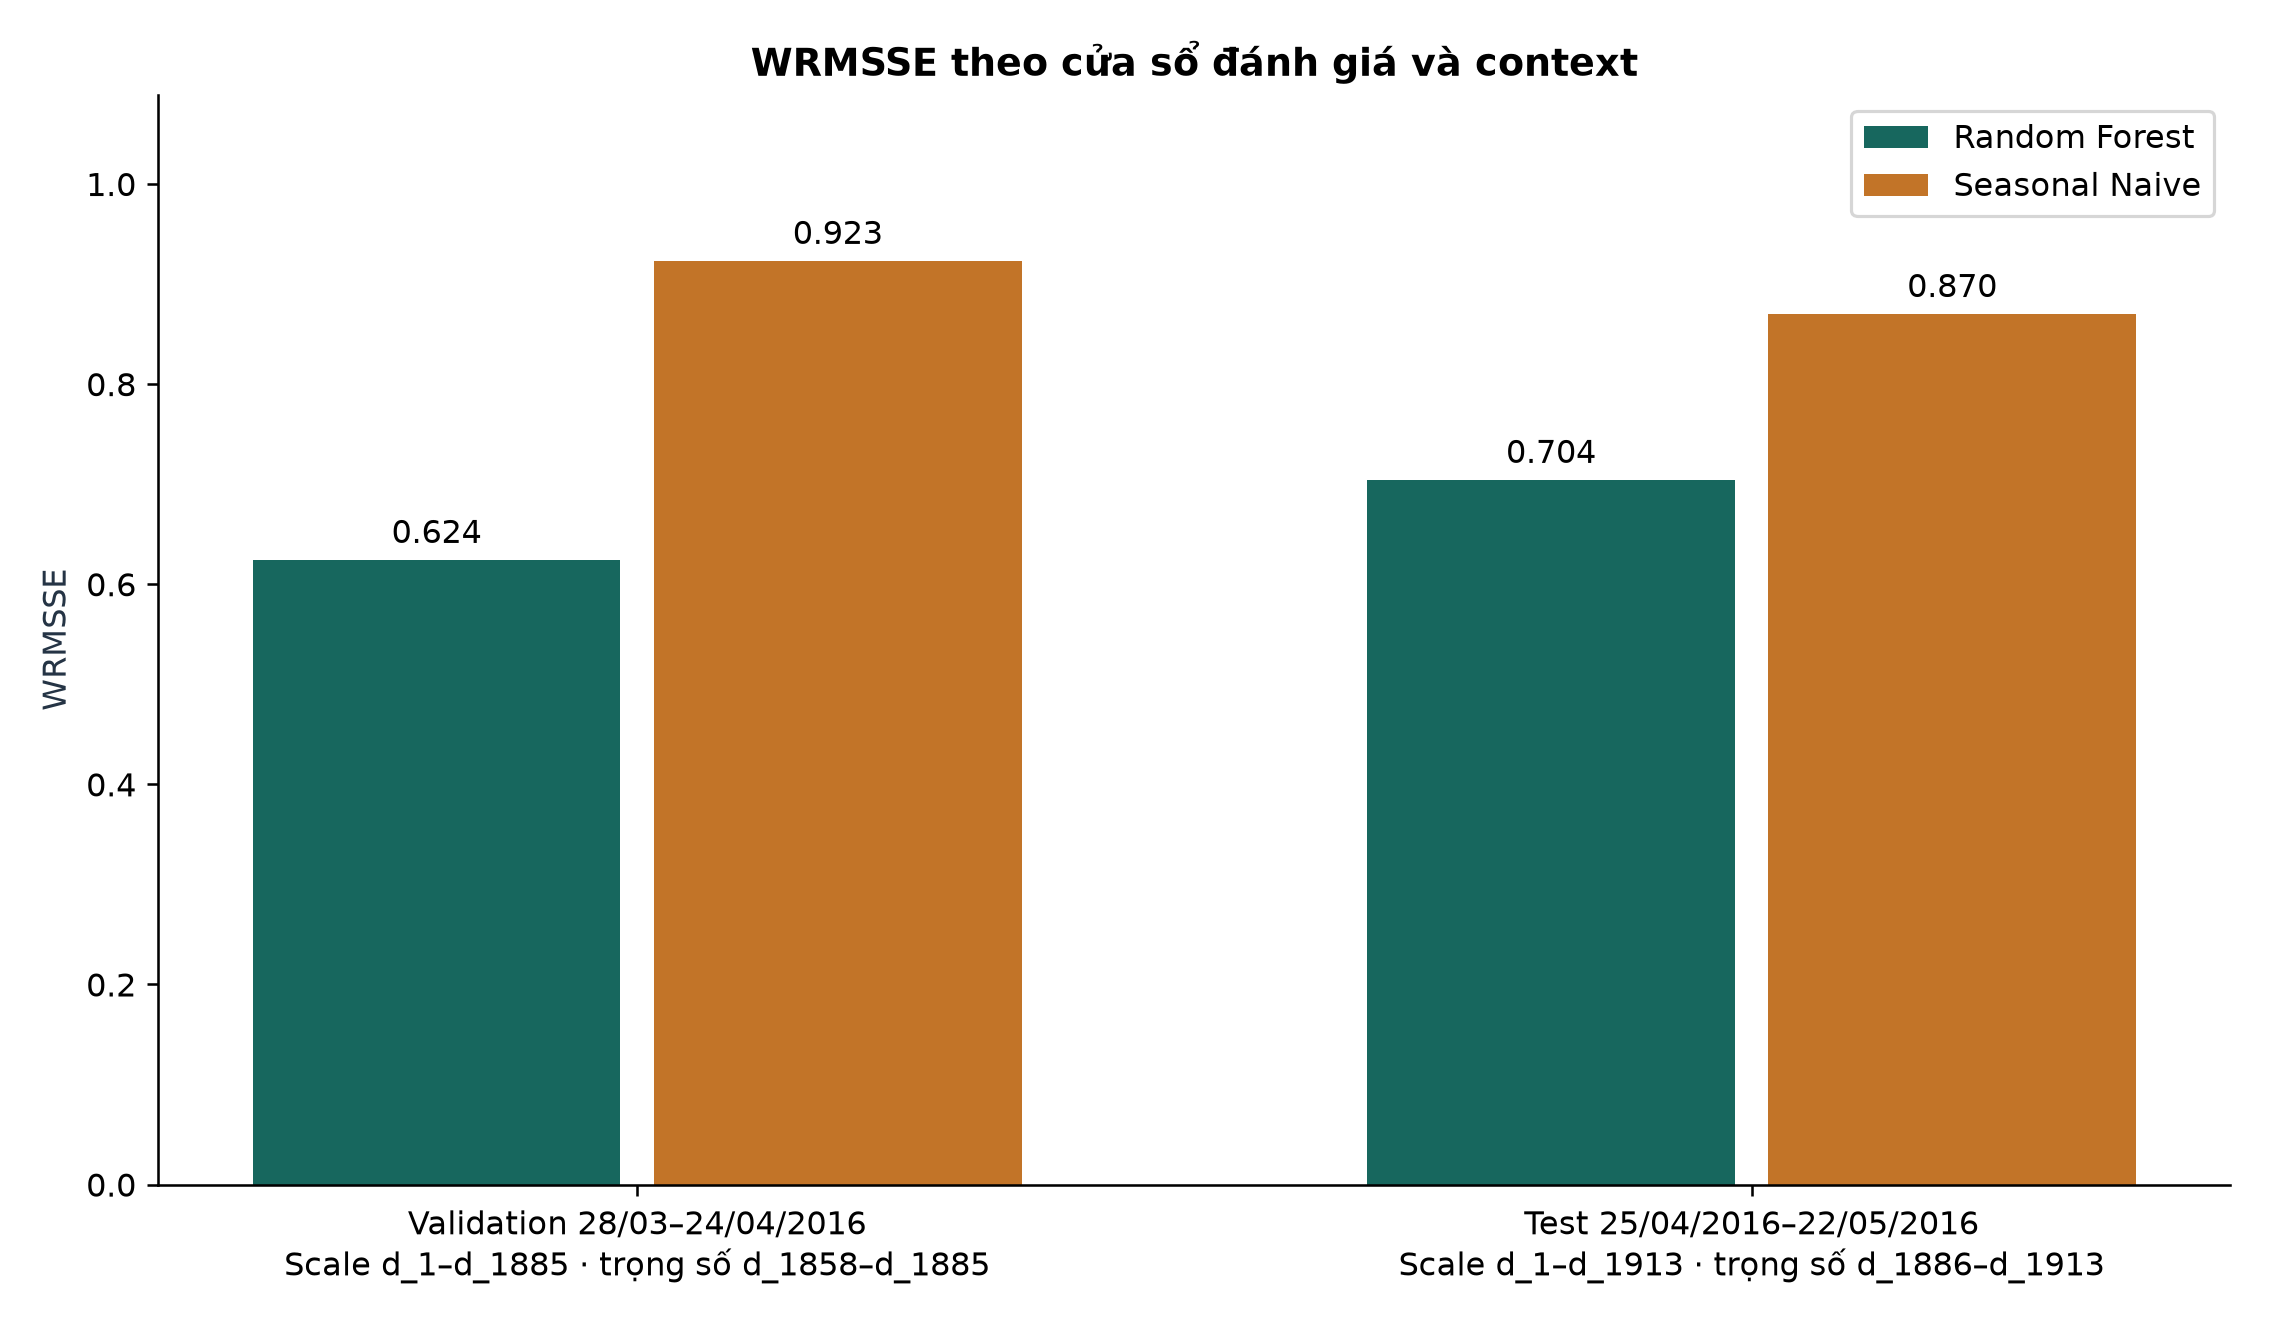

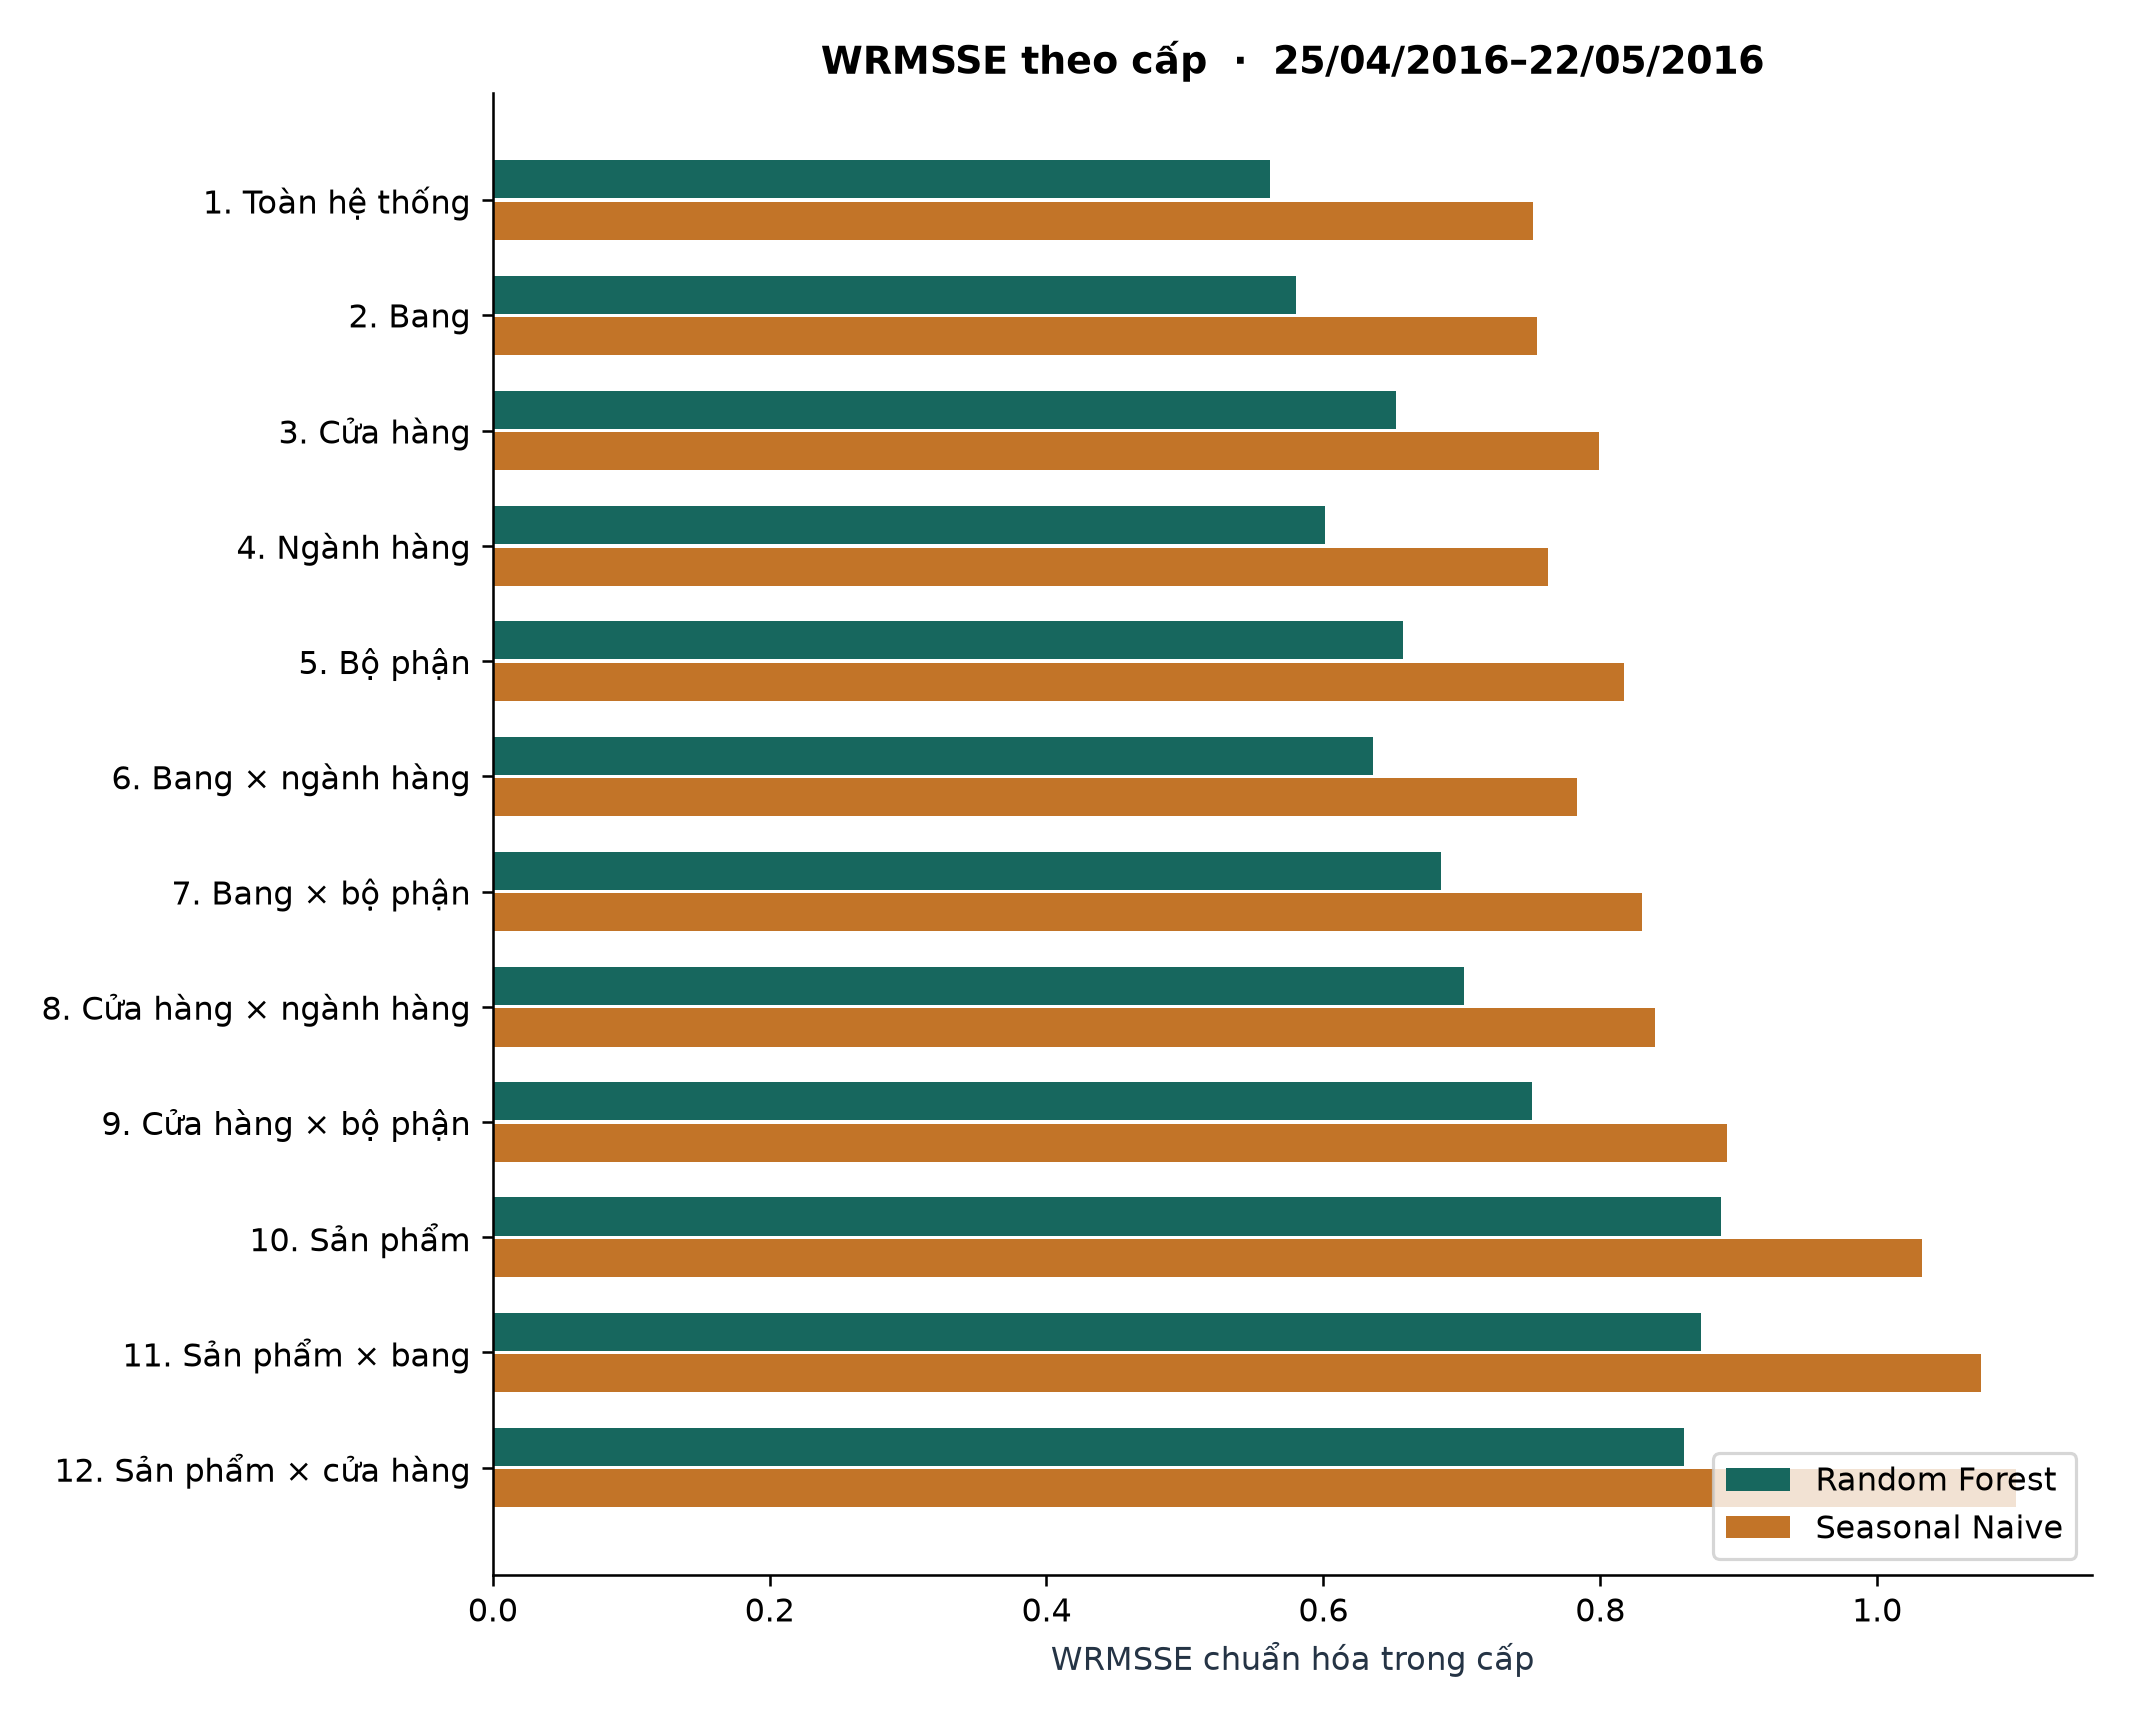

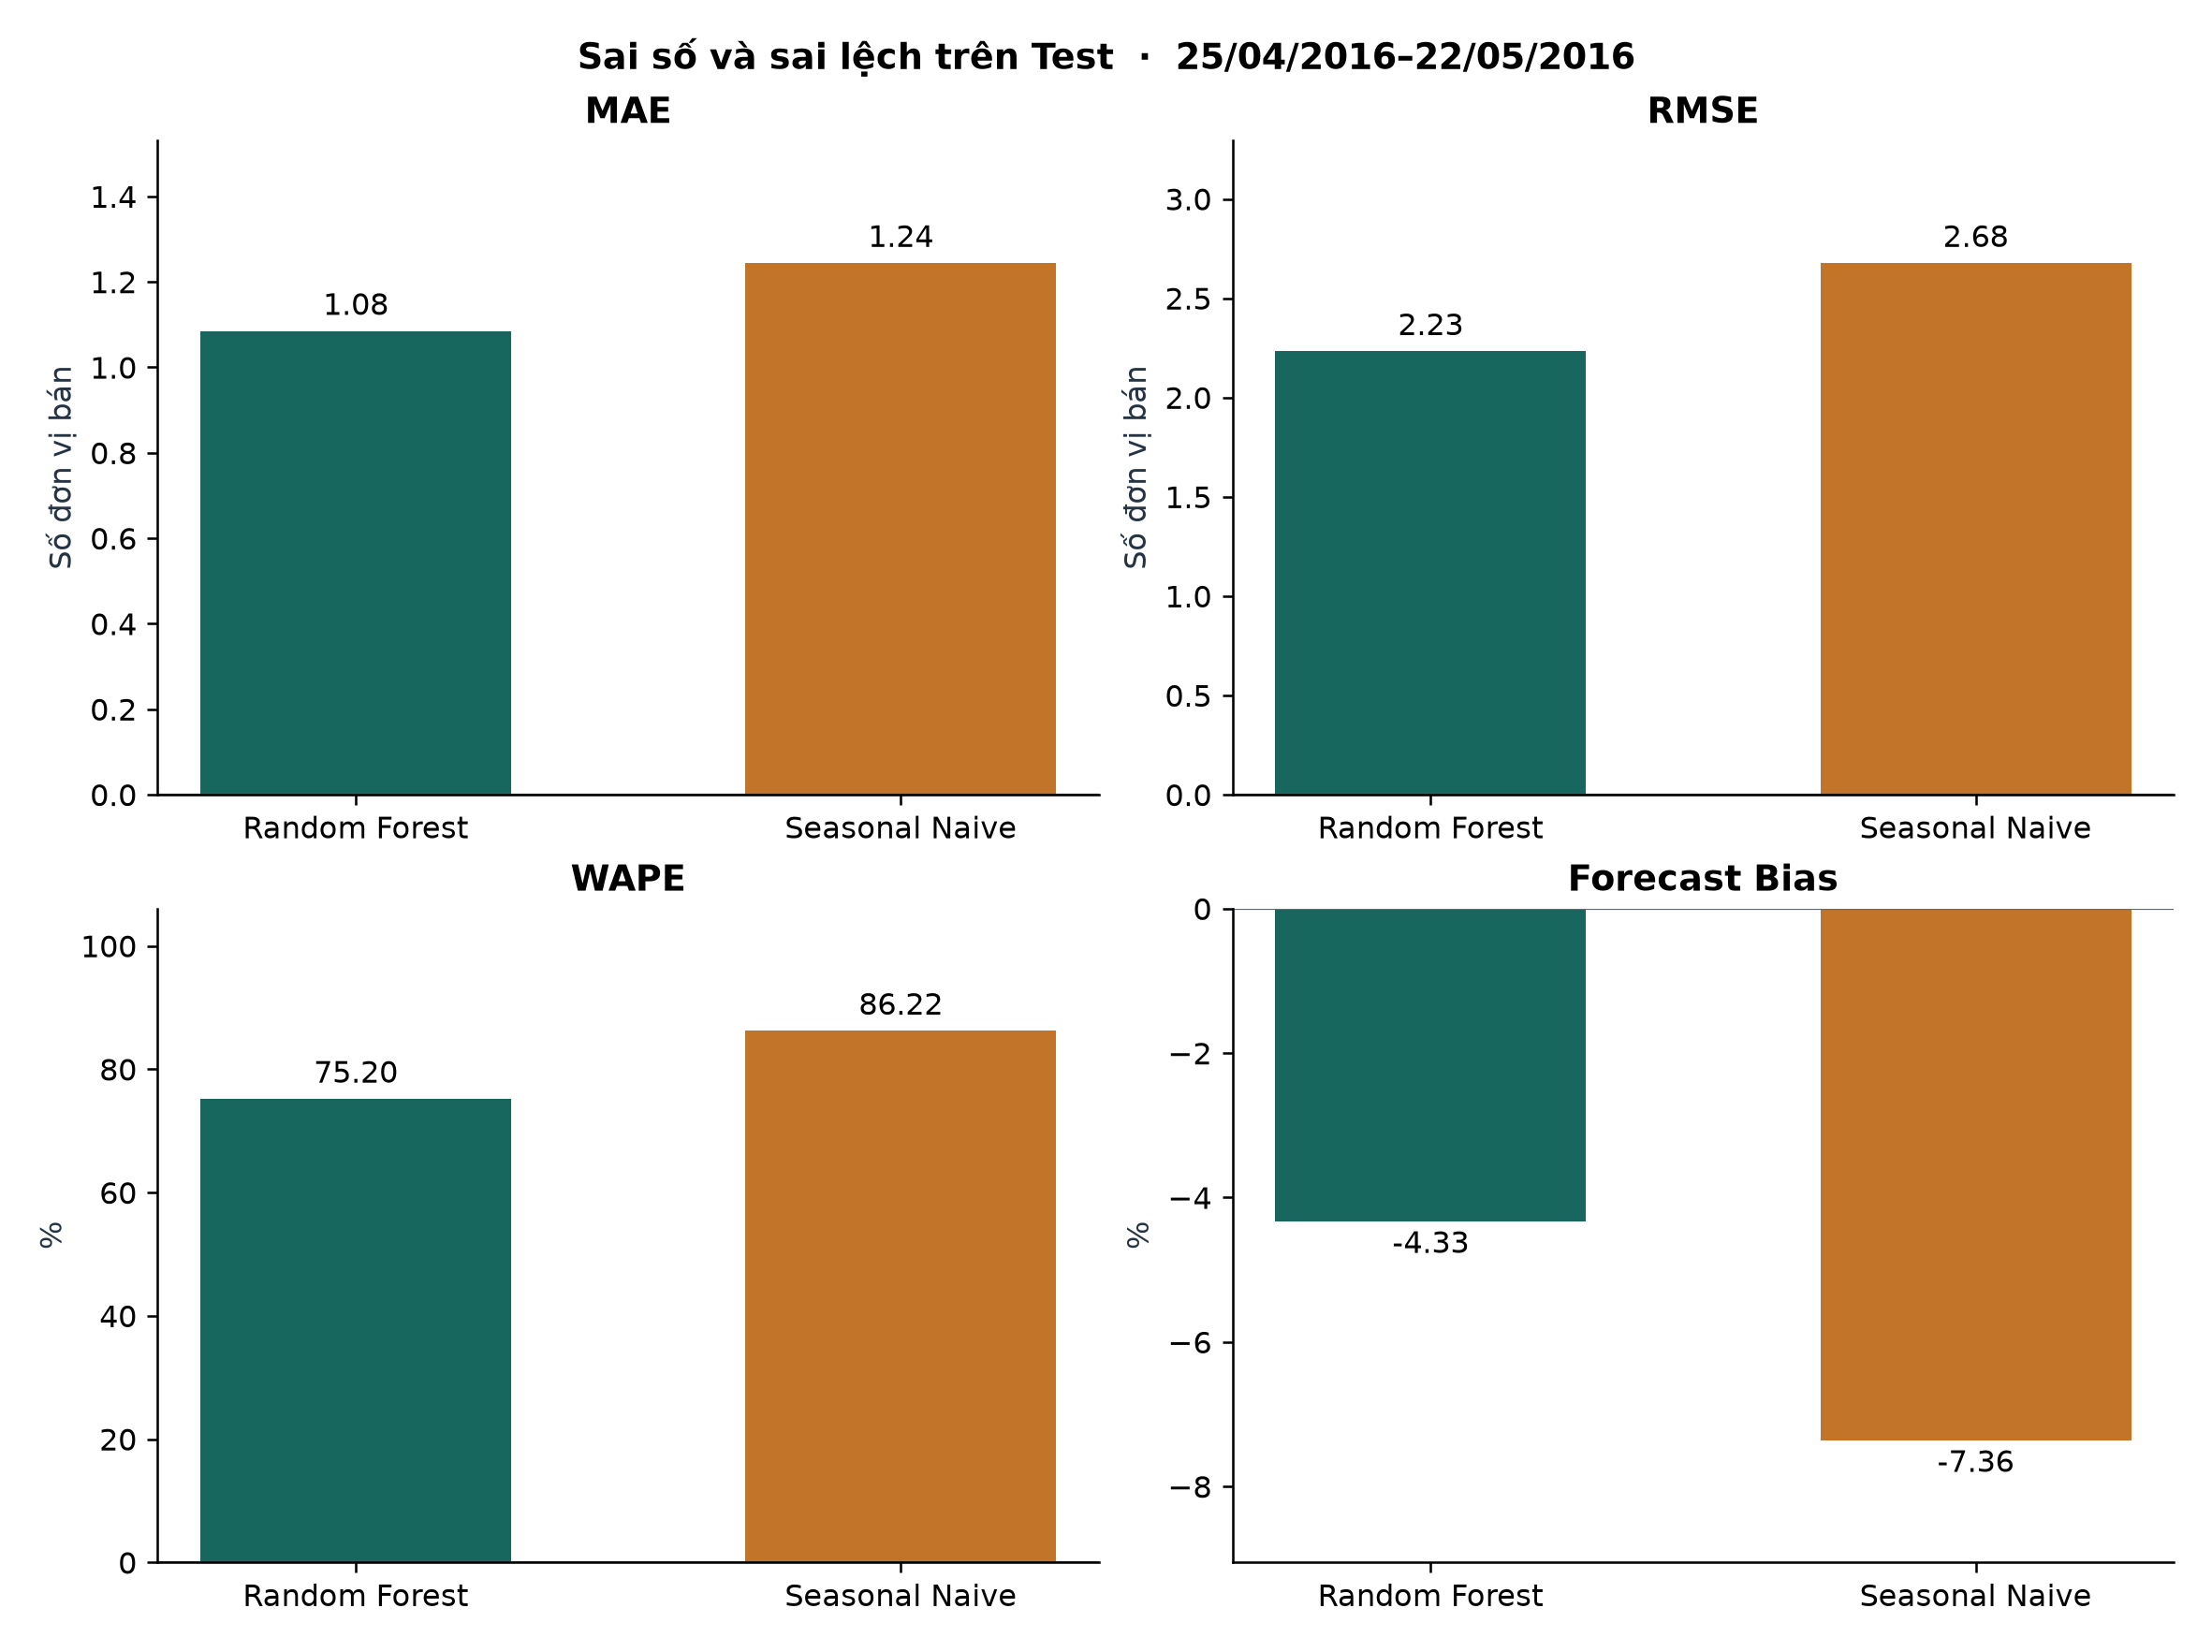

In [2]:
config = read(STAGE4 / "final_model_config.json")
receipt = read(STAGE4 / "resource_summary.json")
display(config)
display({key: receipt[key] for key in ("fit_seconds", "predict_seconds", "peak_worker_rss_mib", "n_jobs", "versions")})
display(table("model_comparison"))
figure(9)
figure(10)
figure(11)
figure(12)

Validation và Test dùng hai cửa sổ cùng các context scale/trọng số khác nhau. Test mới đã từng là Validation của nghiên cứu cũ. Notebook hiển thị kết quả đã khóa của lần chạy WRMSSE.